In [1]:
import os
import shutil
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler 
from torchvision import transforms, datasets, models
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import math
from torchvision.transforms import v2
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

# Reproducibility (Memastikan hasil eksperimen konsisten)
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan Device: {device}")

Menggunakan Device: cuda


In [2]:
#cell 2
class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        return focal_loss.sum()

In [3]:
# 1. Path asal & path tujuan gabungan
PRIMARY_DIR = "/kaggle/input/datasets/adityazianur/skindex/dataset/dataset"
ADDITIONAL_DIR = "/kaggle/input/datasets/adityazianur/skindex/Dataset_Tambahan"
COMBINED_DIR = "/tmp/combined_dataset"

# Reset folder gabungan di temporary directory
if os.path.exists(COMBINED_DIR):
    shutil.rmtree(COMBINED_DIR)
os.makedirs(COMBINED_DIR, exist_ok=True)

# 2. Link semua gambar dari kedua folder tanpa memakan memori disk tambahan
for src_dir in [PRIMARY_DIR, ADDITIONAL_DIR]:
    if not os.path.exists(src_dir):
        continue
    for class_name in os.listdir(src_dir):
        src_class_path = os.path.join(src_dir, class_name)
        if os.path.isdir(src_class_path):
            dst_class_path = os.path.join(COMBINED_DIR, class_name)
            os.makedirs(dst_class_path, exist_ok=True)
            for img_name in os.listdir(src_class_path):
                src_img = os.path.join(src_class_path, img_name)
                dst_img = os.path.join(dst_class_path, f"{os.path.basename(src_dir)}_{img_name}")
                if os.path.isfile(src_img) and not os.path.exists(dst_img):
                    os.symlink(src_img, dst_img)


from PIL import Image
from concurrent.futures import ThreadPoolExecutor

RESIZE = 352
FAST_DIR = "/content/combined_352"
shutil.rmtree(FAST_DIR, ignore_errors=True)   # hapus hasil lama
os.makedirs(FAST_DIR, exist_ok=True)

def prep(args):
    src, dst = args
    if os.path.exists(dst):
        return
    Image.open(src).convert("RGB").resize((RESIZE, RESIZE), Image.BILINEAR).save(dst, quality=95)

jobs = []
for cls in os.listdir(COMBINED_DIR):
    os.makedirs(os.path.join(FAST_DIR, cls), exist_ok=True)
    for f in os.listdir(os.path.join(COMBINED_DIR, cls)):
        jobs.append((os.path.join(COMBINED_DIR, cls, f),
                     os.path.join(FAST_DIR, cls, f + ".jpg"))) 

with ThreadPoolExecutor(8) as ex:
    list(tqdm(ex.map(prep, jobs), total=len(jobs)))


# 3. Load Dataset & Inisialisasi Kelas
DATASET_DIR = FAST_DIR      # ganti dari COMBINED_DIR
full_dataset = datasets.ImageFolder(root=DATASET_DIR)
num_classes = len(full_dataset.classes)
print(f"Total Kelas Penyakit Kulit: {num_classes}")
print(f"Total Gambar Gabungan: {len(full_dataset)}")

IMG = 320
RESIZE = 352   # rasio ~1.1 seperti sebelumnya (256/224), supaya crop tidak terlalu mepet
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((RESIZE, RESIZE)),
    transforms.RandomResizedCrop(IMG, scale=(0.6, 1.0), ratio=(0.85, 1.15)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12)),
])

val_transform = transforms.Compose([
    transforms.Resize((RESIZE, RESIZE)),
    transforms.CenterCrop(IMG),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Custom Subset Wrapper
class TransformedSubset(Dataset):
    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.dataset[self.indices[index]]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.indices)

# 4. Stratified Split Train & Validation (80-20)
targets_np = np.array(full_dataset.targets)
train_idx, val_idx = train_test_split(
    np.arange(len(full_dataset)), 
    test_size=0.2, 
    stratify=targets_np, 
    random_state=42
)

train_dataset = TransformedSubset(full_dataset, train_idx, transform=train_transform)
val_dataset = TransformedSubset(full_dataset, val_idx, transform=val_transform)

# 5. Hitung WeightedRandomSampler
targets = targets_np[train_idx]
cls_count = np.bincount(targets, minlength=num_classes).clip(min=1)
cls_w = 1.0 / np.sqrt(cls_count)
samples_weight = torch.from_numpy(cls_w[targets]).double()
sampler = WeightedRandomSampler(samples_weight, num_samples=len(samples_weight), replacement=True)

# 6. Setup DataLoader
BATCH_SIZE = 32          # kalau OOM -> 24 atau 16
NUM_WORKERS = 4

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, sampler=sampler,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False,   # sebelumnya 64
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True
)

100%|██████████| 32162/32162 [04:13<00:00, 126.81it/s]


Total Kelas Penyakit Kulit: 22
Total Gambar Gabungan: 32162


In [4]:
# Cell 4: Arsitektur Hybrid ConvNeXt-Tiny + ViT
class FlexibleViT(nn.Module):
    def __init__(self):
        super().__init__()
        vit = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
        vit.heads = nn.Identity()
        self.vit = vit

    def forward(self, x):
        # Resize internal khusus cabang ViT ke 224x224
        if x.shape[-2:] != (224, 224):
            x_vit_input = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False, antialias=True)
        else:
            x_vit_input = x
        return self.vit(x_vit_input)

class SkindexHybridModel(nn.Module):
    def __init__(self, num_classes=22):
        super(SkindexHybridModel, self).__init__()
        
        # Cabang 1: ConvNeXt-Tiny (Menerima 256x256 native)
        convnext = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
        self.convnext_features = convnext.features
        self.convnext_pool = convnext.avgpool
        self.convnext_norm = convnext.classifier[0]


        # Cabang 2: ViT-B/16 (via FlexibleViT)
        self.vit_features = FlexibleViT()

        # Proyeksi Dimensi Fitur (768-D -> 512-D)
        self.convnext_proj = nn.Linear(768, 512)
        self.vit_proj = nn.Linear(768, 512)
        
        self.fusion_norm = nn.LayerNorm(1024)

        # Classifier Head
        self.mlp_head = nn.Sequential(
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.SiLU(),
            nn.Dropout(0.5),
            
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.SiLU(),
            nn.Dropout(0.3),
            
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # 1. ConvNeXt olah gambar 256x256
        x_conv = self.convnext_features(x)
        x_conv = self.convnext_pool(x_conv)
        x_conv = self.convnext_norm(x_conv)

        x_conv = torch.flatten(x_conv, 1)
        x_conv = self.convnext_proj(x_conv)

        # 2. ViT olah gambar via resize 224x224
        x_vit = self.vit_features(x)
        x_vit = self.vit_proj(x_vit)

        # 3. Concatenation & Normalization
        x_fused = torch.cat((x_conv, x_vit), dim=1)
        x_fused = self.fusion_norm(x_fused)
        
        return self.mlp_head(x_fused)

In [5]:
model = SkindexHybridModel(num_classes=num_classes).to(device)
 
for p in model.convnext_features.parameters():
    p.requires_grad = False
for p in model.vit_features.parameters():
    p.requires_grad = False
 
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)   # mendukung soft label dari MixUp/CutMix
scaler = torch.amp.GradScaler('cuda')
 
mix_fn = v2.RandomChoice([
    v2.CutMix(num_classes=num_classes, alpha=1.0),
    v2.MixUp(num_classes=num_classes, alpha=0.2),
])
MIX_PROB = 0.5
 
 
def build_stage1_optimizer(model):
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                            lr=1e-3, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 1.0)  # LR konstan saat head-only
    return opt, sched
 
 
def build_stage2_optimizer(model, total_steps, warmup_steps):
    for p in model.parameters():
        p.requires_grad = True
 
    conv_p = [p for n, p in model.named_parameters() if n.startswith("convnext_features")]
    vit_p  = [p for n, p in model.named_parameters() if n.startswith("vit_features")]
    # layer BARU (proj, fusion_norm, convnext_norm, mlp_head) -> LR tinggi
    # (di kode lama layer proj ikut LR backbone 1e-5 -> bug)
    new_p  = [p for n, p in model.named_parameters()
              if not n.startswith(("convnext_features", "vit_features"))]
 
    opt = torch.optim.AdamW([
        {'params': conv_p, 'lr': 1e-4, 'weight_decay': 0.05},
        {'params': vit_p,  'lr': 3e-5, 'weight_decay': 0.05},
        {'params': new_p,  'lr': 5e-4, 'weight_decay': 0.01},
    ])
 
    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))   # cosine 1 siklus, tanpa restart
 
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    return opt, sched

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 219MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 213MB/s]


In [6]:
def train_one_epoch(model, ema, loader, criterion, optimizer, scheduler, scaler, device):
    model.train()
    run_loss, correct, total = 0.0, 0, 0
    loop = tqdm(loader, desc="Training", leave=False)
    for images, labels in loop:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        hard = labels
        if random.random() < MIX_PROB:
            images, labels = mix_fn(images, labels)   # labels jadi soft
 
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels)
 
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()                 # step PER ITERASI
        if ema is not None:
            ema.update_parameters(model)
 
        run_loss += loss.item()
        correct += (outputs.argmax(1) == hard).sum().item()   # akurasi train hanya perkiraan (ada mixup)
        total += hard.size(0)
        loop.set_postfix(loss=loss.item(), acc=100. * correct / total)
    return run_loss / len(loader), 100. * correct / total
 
 
@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()
    run_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, desc="Validation", leave=False):
        images, labels = images.to(device), labels.to(device)
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels)
        run_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return run_loss / len(loader), 100. * correct / total

In [7]:
print("device:", device)
print("cuda available:", torch.cuda.is_available(), "| jumlah GPU:", torch.cuda.device_count())
print("model di:", next(model.parameters()).device)
!nvidia-smi

device: cuda
cuda available: True | jumlah GPU: 2
model di: cuda:0
Tue Nov  3 03:59:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P0             26W /   70W |     593MiB /  15360MiB |      0%      Default |
|                                         |                        |     

In [8]:
EPOCHS = 30
FREEZE_EPOCHS = 2
steps_per_epoch = len(train_loader)
SAVE_PATH = "/kaggle/working/best_skindex_v5_320.pt"

optimizer, scheduler = build_stage1_optimizer(model)
ema = None
best_val_acc = 0.0

for epoch in range(EPOCHS):
    if epoch == FREEZE_EPOCHS:
        print("\n>>> UNFREEZE: fine-tuning seluruh jaringan (LR per grup, warmup + cosine) <<<\n")
        total_steps = (EPOCHS - FREEZE_EPOCHS) * steps_per_epoch
        optimizer, scheduler = build_stage2_optimizer(model, total_steps, warmup_steps=steps_per_epoch)
        ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(0.999), use_buffers=True)

    train_loss, train_acc = train_one_epoch(model, ema, train_loader, criterion, optimizer, scheduler, scaler, device)

    eval_model = ema if ema is not None else model
    val_loss, val_acc = validate(eval_model, val_loader, criterion, device)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {train_loss:.4f} - Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} - Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        sd = ema.module.state_dict() if ema is not None else model.state_dict()
        torch.save(sd, SAVE_PATH)
        print(f"--> Model terbaik disimpan: {val_acc:.2f}%")

    # checkpoint tiap epoch (di dalam loop)
    torch.save({
        "model": model.state_dict(),
        "ema": ema.module.state_dict() if ema is not None else None,
        "opt": optimizer.state_dict(), "sched": scheduler.state_dict(),
        "epoch": epoch, "best": best_val_acc,
    }, "/kaggle/working/last.pt")

Epoch [1/30] | Train Loss: 1.9978 - Acc: 41.16% | Val Loss: 1.5604 - Acc: 60.05%
--> Model terbaik disimpan: 60.05%


Epoch [2/30] | Train Loss: 1.8346 - Acc: 47.82% | Val Loss: 1.4746 - Acc: 63.97%
--> Model terbaik disimpan: 63.97%

>>> UNFREEZE: fine-tuning seluruh jaringan (LR per grup, warmup + cosine) <<<



Epoch [3/30] | Train Loss: 1.7171 - Acc: 53.05% | Val Loss: 1.3637 - Acc: 68.97%
--> Model terbaik disimpan: 68.97%


Epoch [4/30] | Train Loss: 1.5950 - Acc: 57.30% | Val Loss: 1.2376 - Acc: 74.37%
--> Model terbaik disimpan: 74.37%


Epoch [5/30] | Train Loss: 1.4763 - Acc: 61.91% | Val Loss: 1.1521 - Acc: 77.71%
--> Model terbaik disimpan: 77.71%


Epoch [6/30] | Train Loss: 1.4094 - Acc: 63.46% | Val Loss: 1.0866 - Acc: 80.40%
--> Model terbaik disimpan: 80.40%


... (20 outputs left out)

Epoch [27/30] | Train Loss: 0.9679 - Acc: 78.64% | Val Loss: 0.9057 - Acc: 89.48%


Epoch [28/30] | Train Loss: 0.9688 - Acc: 80.03% | Val Loss: 0.9058 - Acc: 89.57%
--> Model terbaik disimpan: 89.57%


Epoch [29/30] | Train Loss: 0.9834 - Acc: 79.15% | Val Loss: 0.9056 - Acc: 89.48%


Epoch [30/30] | Train Loss: 0.9769 - Acc: 80.21% | Val Loss: 0.9058 - Acc: 89.48%


TTA: 100%|██████████| 202/202 [02:46<00:00,  1.21it/s]


TTA Acc: 89.46%
                            precision    recall  f1-score   support

                      Acne       0.88      0.95      0.91       597
         Actinic keratosis       1.00      1.00      1.00       227
          Benign keratosis       0.88      0.91      0.89       571
                 Cacar Air       0.93      0.91      0.92        43
                Cellulitis       0.87      0.62      0.73       106
            Dermatofibroma       1.00      1.00      1.00       228
                       Dry       0.89      0.86      0.87       152
   Eczema_Dermatitis_Group       0.84      0.84      0.84      1003
             Herpes Zoster       0.85      0.88      0.87       406
                  Impetigo       0.88      0.93      0.90        30
                Jamur Kuku       0.87      0.89      0.88       293
                  Kutu Air       0.91      0.98      0.94        41
             Larva Migrans       0.97      0.97      0.97        29
         Melanocytic nevus     

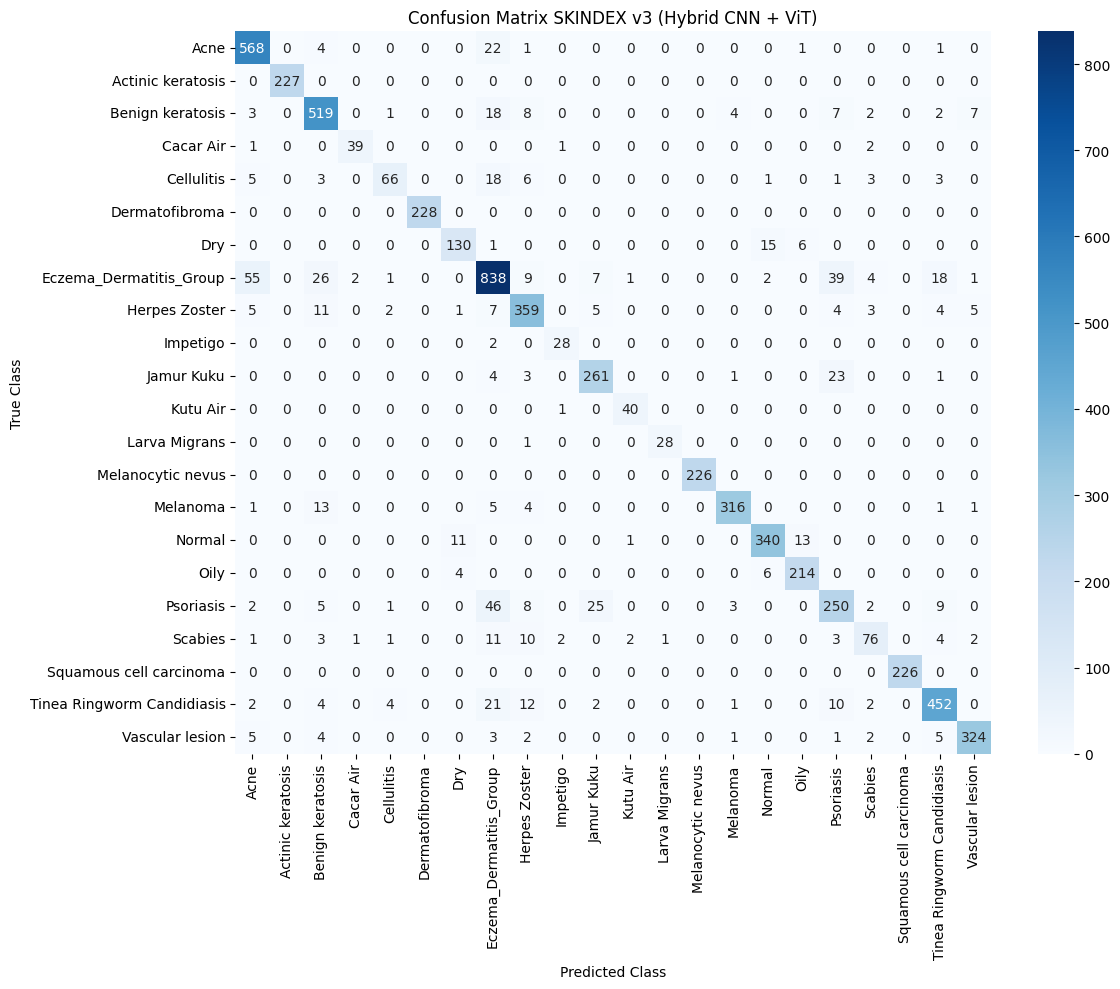

In [9]:
# Load weights dengan aman dari folder working Kaggle
model.load_state_dict(torch.load(SAVE_PATH))
model.eval()
 
@torch.no_grad()
def predict_tta(model, loader):
    probs, labs = [], []
    for x, y in tqdm(loader, desc="TTA"):
        x = x.to(device)
        with torch.amp.autocast('cuda'):
            p = (F.softmax(model(x), 1)
                 + F.softmax(model(x.flip(3)), 1)          # hflip
                 + F.softmax(model(x.flip(2)), 1)          # vflip
                 + F.softmax(model(x.flip(2).flip(3)), 1)) / 4
        probs.append(p.float().cpu()); labs.append(y)
    return torch.cat(probs), torch.cat(labs)
 
probs, labs = predict_tta(model, val_loader)
all_preds, all_labels = probs.argmax(1).numpy(), labs.numpy()
print(f"TTA Acc: {(all_preds == all_labels).mean() * 100:.2f}%")
print(classification_report(all_labels, all_preds, target_names=full_dataset.classes))

# Tampilkan Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=full_dataset.classes, 
    yticklabels=full_dataset.classes
)
plt.title('Confusion Matrix SKINDEX v3 (Hybrid CNN + ViT)')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()